# Information Extraction Pipeline
POS Tagging, NER, Relation Extraction, Event Extraction, Temporal Ordering

In [ ]:
!pip -q install spacy pandas networkx matplotlib dateparser
!python -m spacy download en_core_web_sm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.5/316.5 kB 5.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 87.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import spacy,pandas as pd,networkx as nx,matplotlib.pyplot as plt
nlp=spacy.load("en_core_web_sm")
text='''Barack Obama visited India on 21 June 2023. He met Prime Minister Narendra Modi in New Delhi. They signed a trade agreement on 22 June 2023.'''
doc=nlp(text)

## POS Tagging

In [ ]:
pos=pd.DataFrame([{'Token':t.text,'POS':t.pos_} for t in doc])
display(pos)

,Token,POS
0,Barack,PROPN
1,Obama,PROPN
2,visited,VERB
3,India,PROPN
4,on,ADP
5,21,NUM
6,June,PROPN
7,2023,NUM
8,.,PUNCT
9,He,PRON


## Named Entities

In [ ]:
entities=pd.DataFrame([{'Entity':e.text,'Label':e.label_} for e in doc.ents])
display(entities)
entities.to_csv('entities.csv',index=False)

,Entity,Label
0,Barack Obama,PERSON
1,India,GPE
2,21 June 2023,DATE
3,Narendra Modi,PERSON
4,New Delhi,GPE
5,22 June 2023,DATE


## Relation Extraction

In [ ]:
rels=[]
for sent in doc.sents:
    for tok in sent:
        if tok.dep_=='ROOT':
            s=o=''
            for c in tok.children:
                if c.dep_ in ('nsubj','nsubjpass'): s=c.text
                if c.dep_ in ('dobj','pobj','attr'): o=c.text
            if s and o:
                rels.append({'Subject':s,'Relation':tok.lemma_,'Object':o})
relations=pd.DataFrame(rels)
display(relations)
relations.to_csv('relations.csv',index=False)

,Subject,Relation,Object
0,Obama,visit,India
1,He,meet,Modi
2,They,sign,agreement


## Event Extraction

In [ ]:
events=[]
for sent in doc.sents:
    ds=[e.text for e in sent.ents if e.label_=='DATE']
    for t in sent:
        if t.pos_=='VERB':
            events.append({'Event':t.lemma_,'Date':', '.join(ds),'Sentence':sent.text})
events=pd.DataFrame(events)
display(events)
events.to_csv('events.csv',index=False)

,Event,Date,Sentence
0,visit,21 June 2023,Barack Obama visited India on 21 June 2023.
1,meet,,He met Prime Minister Narendra Modi in New Delhi.
2,sign,22 June 2023,They signed a trade agreement on 22 June 2023.


## Timeline

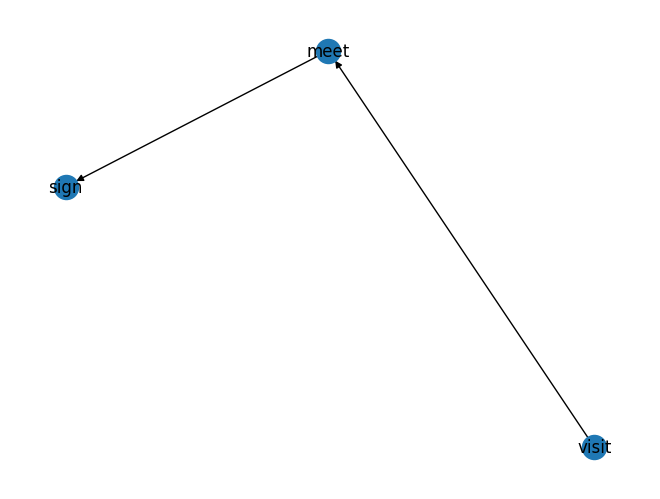

In [ ]:
G=nx.DiGraph()
for i in range(len(events)-1):
    G.add_edge(events.iloc[i]['Event'],events.iloc[i+1]['Event'])
nx.draw(G,with_labels=True)
plt.savefig('timeline.png')
plt.show()

## Pipeline Report

In [ ]:
print(f'''Pipeline:
1. spaCy preprocessing
2. POS tagging
3. Named Entity Recognition
4. Rule-based Relation Extraction
5. Verb-based Event Extraction
6. Timeline Generation

Entities: {len(entities)}
Relations: {len(relations)}
Events: {len(events)}
''')

Pipeline:
1. spaCy preprocessing
2. POS tagging
3. Named Entity Recognition
4. Rule-based Relation Extraction
5. Verb-based Event Extraction
6. Timeline Generation

Entities: 6
Relations: 3
Events: 3

